In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

In [2]:
df=pd.read_csv("cleaned_eurusd.csv")
df.head(10)

,Date,BO,BH,BL,BC,BCh,AO,AH,AL,AC,ACh,Price_Change,Price_Change_%,Year,Month,Season,B_volatility,A_volatility,Price_range
0,2005-05-02,1.28520,1.28740,1.28367,1.28540,0.00020,1.28540,1.28755,1.28387,1.28560,0.00020,0.00020,0.02,2005,May,Spring,0.00373,0.00368,"(1.262, 1.318]"
1,2005-05-03,1.28550,1.29135,1.28300,1.28783,0.00223,1.28570,1.29185,1.28320,1.28798,0.00218,0.00233,0.18,2005,May,Spring,0.00835,0.00865,"(1.262, 1.318]"
2,2005-05-04,1.28783,1.29733,1.28763,1.29430,0.00657,1.28798,1.29748,1.28778,1.29450,0.00662,0.00647,0.50,2005,May,Spring,0.00970,0.00970,"(1.262, 1.318]"
3,2005-05-05,1.29430,1.29885,1.29263,1.29450,0.00050,1.29450,1.29900,1.29278,1.29470,0.00050,0.00020,0.02,2005,May,Spring,0.00622,0.00622,"(1.262, 1.318]"
4,2005-05-06,1.29450,1.29630,1.28103,1.28140,-0.01300,1.29470,1.29645,1.28118,1.28240,-0.01220,-0.01310,-1.01,2005,May,Spring,0.01527,0.01527,"(1.262, 1.318]"
5,2005-05-08,1.28125,1.28180,1.28090,1.28100,-0.00020,1.28225,1.28280,1.28190,1.28200,-0.00020,-0.00025,-0.02,2005,May,Spring,0.00090,0.00090,"(1.262, 1.318]"
6,2005-05-09,1.28140,1.28760,1.27893,1.28450,0.00290,1.28160,1.28775,1.27908,1.28465,0.00285,0.00310,0.24,2005,May,Spring,0.00867,0.00867,"(1.262, 1.318]"
7,2005-05-10,1.28450,1.28893,1.28160,1.28775,0.00305,1.28465,1.28908,1.28175,1.28790,0.00305,0.00325,0.25,2005,May,Spring,0.00733,0.00733,"(1.262, 1.318]"
8,2005-05-11,1.28775,1.29115,1.27766,1.28030,-0.00735,1.28790,1.29130,1.27781,1.28045,-0.00735,-0.00745,-0.58,2005,May,Spring,0.01349,0.01349,"(1.262, 1.318]"
9,2005-05-12,1.28020,1.28075,1.26660,1.26815,-0.01210,1.28035,1.28090,1.26680,1.26830,-0.01210,-0.01205,-0.94,2005,May,Spring,0.01415,0.01410,"(1.262, 1.318]"


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4672 entries, 0 to 4671
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            4672 non-null   object 
 1   BO              4672 non-null   float64
 2   BH              4672 non-null   float64
 3   BL              4672 non-null   float64
 4   BC              4672 non-null   float64
 5   BCh             4672 non-null   float64
 6   AO              4672 non-null   float64
 7   AH              4672 non-null   float64
 8   AL              4672 non-null   float64
 9   AC              4672 non-null   float64
 10  ACh             4672 non-null   float64
 11  Price_Change    4672 non-null   float64
 12  Price_Change_%  4672 non-null   float64
 13  Year            4672 non-null   int64  
 14  Month           4672 non-null   object 
 15  Season          4672 non-null   object 
 16  B_volatility    4672 non-null   float64
 17  A_volatility    4672 non-null   f

##
<span style="font-size:40px; color:blue;">**1. Data Preparation**</span>

In [4]:
df["Date"]=pd.to_datetime(df["Date"])
print(df["Date"].dtype)
df=df.sort_values(by="Date",ascending=True)
df.head(5)


datetime64[ns]


,Date,BO,BH,BL,BC,BCh,AO,AH,AL,AC,ACh,Price_Change,Price_Change_%,Year,Month,Season,B_volatility,A_volatility,Price_range
0,2005-05-02,1.28520,1.28740,1.28367,1.28540,0.00020,1.28540,1.28755,1.28387,1.28560,0.00020,0.00020,0.02,2005,May,Spring,0.00373,0.00368,"(1.262, 1.318]"
1,2005-05-03,1.28550,1.29135,1.28300,1.28783,0.00223,1.28570,1.29185,1.28320,1.28798,0.00218,0.00233,0.18,2005,May,Spring,0.00835,0.00865,"(1.262, 1.318]"
2,2005-05-04,1.28783,1.29733,1.28763,1.29430,0.00657,1.28798,1.29748,1.28778,1.29450,0.00662,0.00647,0.50,2005,May,Spring,0.00970,0.00970,"(1.262, 1.318]"
3,2005-05-05,1.29430,1.29885,1.29263,1.29450,0.00050,1.29450,1.29900,1.29278,1.29470,0.00050,0.00020,0.02,2005,May,Spring,0.00622,0.00622,"(1.262, 1.318]"
4,2005-05-06,1.29450,1.29630,1.28103,1.28140,-0.01300,1.29470,1.29645,1.28118,1.28240,-0.01220,-0.01310,-1.01,2005,May,Spring,0.01527,0.01527,"(1.262, 1.318]"


In [5]:
df["Next_day_change"]=df["Price_Change"].shift(-1)
ml_df = df[["Date","Price_Change","Next_day_change"]]
print(ml_df.head(5))
print(ml_df.isnull().sum())

        Date  Price_Change  Next_day_change
0 2005-05-02       0.00020          0.00233
1 2005-05-03       0.00233          0.00647
2 2005-05-04       0.00647          0.00020
3 2005-05-05       0.00020         -0.01310
4 2005-05-06      -0.01310         -0.00025
Date               0
Price_Change       0
Next_day_change    1
dtype: int64


In [6]:
ml_df = ml_df.dropna()
ml_df.isnull().sum()


Date               0
Price_Change       0
Next_day_change    0
dtype: int64

In [7]:
x=ml_df["Price_Change"]
y=ml_df["Next_day_change"]
len(ml_df)

4671

In [8]:
train_data= int((len(ml_df)*80)/100)
train_data
#test_data= int((len(ml_df)*20)/100)
#test_data


3736

In [9]:
x_train=x.iloc[0:train_data]
y_train=y.iloc[0:train_data]
x_test=x.iloc[train_data:len(ml_df)]
y_test=y.iloc[train_data:len(ml_df)]




In [10]:
val_split = int(len(x_train) * 0.90)

x_train_new = x_train.iloc[:val_split]
y_train_new = y_train.iloc[:val_split]

x_val = x_train.iloc[val_split:]
y_val = y_train.iloc[val_split:]

print(len(x_train_new), len(x_val))

3362 374


##
<span style="font-size:40px; color:red;">**2. Baseline Model**</span>


In [11]:
baseline_val_pred = np.zeros(len(y_val))
baseline_val_mae = mean_absolute_error(y_val, baseline_val_pred)
print(baseline_val_mae)

0.0034691711229945946


##
<span style="font-size:40px; color:pink;">**3. Model Experiment**</span>

In [12]:
#linear Regression Model
model=LinearRegression()
model.fit(x_train_new.to_frame(),y_train_new)

LinearRegression()

In [13]:
lr_val_pred= model.predict(x_val.to_frame())
lr_val_pred[:5]


array([-5.14180160e-05, -5.44583609e-05, -6.12946394e-05, -5.91942828e-05,
       -5.71973699e-05])

In [14]:
lr_val_pred_mae=mean_absolute_error(y_val,lr_val_pred)
lr_val_pred_mae

0.003468839080017442

##
<span style="font-size:40px; color:yellow;">**4. Baseline Model Prediction**</span>

In [15]:
baseline_pred = np.zeros(len(y_test))
baseline_mae=mean_absolute_error(y_test,baseline_pred)
baseline_mae


0.003181828877005301

##
<span style="font-size:40px; color:green;">**5. Linear Regression with two Feature**</span>

In [16]:
#create multidimentional model to check whether the model more accuraye
#Add the B_volatility column into ml_df table
ml_df["B_volatility"]=df.loc[ml_df.index,"B_volatility"]
ml_df.head(5)


,Date,Price_Change,Next_day_change,B_volatility
0,2005-05-02,0.00020,0.00233,0.00373
1,2005-05-03,0.00233,0.00647,0.00835
2,2005-05-04,0.00647,0.00020,0.00970
3,2005-05-05,0.00020,-0.01310,0.00622
4,2005-05-06,-0.01310,-0.00025,0.01527


In [17]:
#Extracted the Bo_volatility column to create a model
x1= ml_df[["Price_Change", "B_volatility"]]
#Extract 80% data from x1
x1_train= x1.iloc[0:3736]
x1_test=x1.iloc[3736:len(ml_df)]
x1_train_new = x1_train.iloc[:val_split]
x1_val = x1_train.iloc[val_split:]
#Now data is fitted into model
model1=LinearRegression()
model1.fit(x1_train_new,y_train_new)
# Predict on the validation set
lr_two_val_pred = model1.predict(x1_val)
lr_two_val_pred[:5]


array([-0.00041537, -0.00022391, -0.00013292,  0.00019945, -0.00011845])

In [18]:
#Calculated the absulate errors
lr_two_val_mae=mean_absolute_error(y_val,lr_two_val_pred)
lr_two_val_mae

0.0034708210454820875

In [19]:
lr_two_val_mae-baseline_val_mae

1.6499224874929122e-06

In [20]:
#checked correlation between 3 columns of ml_df table
ml_df.iloc[:val_split][["Price_Change","B_volatility","Next_day_change"]].corr()

,Price_Change,B_volatility,Next_day_change
Price_Change,1.000000,-0.010710,0.000449
B_volatility,-0.010710,1.000000,-0.024475
Next_day_change,0.000449,-0.024475,1.000000


### In the training data, both `Price_Change` and `B_volatility` have very weak linear correlations with `Next_day_change`. I will evaluate a Decision Tree Regressor on the same validation set to see whether it reduces MAE.

In [21]:
#Decesion tree
tree_model=DecisionTreeRegressor(max_depth=3,random_state=42)
tree_model.fit(x1_train_new,y_train_new)
tree_val_pred=tree_model.predict(x1_val)
tree_val_mae=mean_absolute_error(y_val,tree_val_pred)
tree_val_mae

0.003481098372304091

In [22]:
#generating tree_3 model
tree_3=DecisionTreeRegressor(max_depth=3,random_state=42)
tree_3.fit(x1_train_new,y_train_new)
y3_pred=tree_3.predict(x1_val)
tree_3_mae = mean_absolute_error(y_val,y3_pred)
print(f"tree_3_mae : {tree_3_mae}")

#generating tree_5 model
tree_5=DecisionTreeRegressor(max_depth=5,random_state=42)
tree_5.fit(x1_train_new,y_train_new)
y5_pred=tree_5.predict(x1_val)
tree_5_mae = mean_absolute_error(y_val,y5_pred)
print(f"tree_5_mae : {tree_5_mae}")

#generating tree_10 model
tree_10=DecisionTreeRegressor(max_depth=10,random_state=42)
tree_10.fit(x1_train_new,y_train_new)
y10_pred=tree_10.predict(x1_val)
tree_10_mae = mean_absolute_error(y_val,y10_pred)
print(f"tree_10_mae : {tree_10_mae}")


tree_3_mae : 0.003481098372304091
tree_5_mae : 0.003481603180590567
tree_10_mae : 0.0035300513019949943


### Decision Tree with Price Ranges

In [23]:
#now generating new model with new feature
ml_df["BC"]= df.loc[ml_df.index,"BC"]
new_df=ml_df[["BC","Next_day_change"]].copy()
new_df.head()


,BC,Next_day_change
0,1.28540,0.00233
1,1.28783,0.00647
2,1.29430,0.00020
3,1.29450,-0.01310
4,1.28140,-0.00025


In [24]:
#splitting data
new_train=new_df.iloc[:train_data]
new_test = new_df.iloc[train_data:]
print(len(new_train))
print(len(new_test))





3736
935


In [25]:
#conver "BC" into price range
price_range,bins=pd.cut(new_train["BC"],bins=10,retbins=True)
print(bins)
#Added price_range column in new_train dataframe
new_train=new_train.copy()#used .copy() that the previous new train dataframe is not affected
new_train["price_range"] = price_range
new_train.head()



[1.03846165 1.094855   1.15069    1.206525   1.26236    1.318195
 1.37403    1.429865   1.4857     1.541535   1.59737   ]


,BC,Next_day_change,price_range
0,1.28540,0.00233,"(1.262, 1.318]"
1,1.28783,0.00647,"(1.262, 1.318]"
2,1.29430,0.00020,"(1.262, 1.318]"
3,1.29450,-0.01310,"(1.262, 1.318]"
4,1.28140,-0.00025,"(1.262, 1.318]"


In [26]:
#Added price_range column in new_test dataframe
new_test=new_test.copy()#used .copy() that the previous new test dataframe is not affected
price_range=pd.cut(new_test["BC"],bins=bins)
new_test["price_range"]=price_range
print(new_test.head())

#Cheeking the nall value of "price change" in new test data set
print(new_test["price_range"].isnull().sum())

           BC  Next_day_change     price_range
3736  1.08728         -0.00086  (1.038, 1.095]
3737  1.08644          0.00626  (1.038, 1.095]
3738  1.09271         -0.00195  (1.038, 1.095]
3739  1.09078         -0.00429  (1.038, 1.095]
3740  1.08647          0.00263  (1.038, 1.095]
0


In [27]:

train_final= new_train.iloc[:val_split].copy()
val_final=new_train.iloc[val_split:].copy()
print(len(train_final))

print(len(val_final))




3362
374


In [28]:
#now calculated "price range" by the train_final
final_range,bins=pd.cut(train_final["BC"],bins=10,retbins=True)
print(bins)
train_final["price_range"]= final_range
print(train_final.head())



[1.04777095 1.103225   1.15813    1.213035   1.26794    1.322845
 1.37775    1.432655   1.48756    1.542465   1.59737   ]
        BC  Next_day_change     price_range
0  1.28540          0.00233  (1.268, 1.323]
1  1.28783          0.00647  (1.268, 1.323]
2  1.29430          0.00020  (1.268, 1.323]
3  1.29450         -0.01310  (1.268, 1.323]
4  1.28140         -0.00025  (1.268, 1.323]


In [29]:
#now calculated "price range" by the val_final
val_final["price_range"]=pd.cut(val_final["BC"],bins=bins)
val_final.head()
missing_value=val_final.isnull().sum()
missing_value

BC                  0
Next_day_change     0
price_range        12
dtype: int64

In [30]:
#now lets check which data have null values
val_final.loc[val_final["price_range"].isnull(),["BC","price_range"]]

,BC,price_range
3629,1.04462,NaN
3630,1.04460,NaN
3631,1.04019,NaN
3632,1.03902,NaN
3633,1.04257,NaN
3634,1.04370,NaN
3635,1.04502,NaN
3636,1.04531,NaN
3637,1.04604,NaN
3638,1.04135,NaN


In [31]:
#we will bring the nan price range data into minmum or maximum price range
extented_bins= bins.copy()
extented_bins[0]=-np.inf #open the minmum boundary of first range
extented_bins[-1]=np.inf #open the maximum boundary of last range
# Now include all "BC" into price range
val_final["price_range"]= pd.cut(val_final["BC"],bins=extented_bins)
print(val_final.isnull().sum())
train_final["price_range"]= pd.cut(train_final["BC"],bins=extented_bins)
# now we well convert price ranges into number
train_final["price_range"]=train_final["price_range"].cat.codes +1
val_final["price_range"]=val_final["price_range"].cat.codes +1
print(train_final["price_range"])
print(val_final["price_range"])

BC                 0
Next_day_change    0
price_range        0
dtype: int64
0       5
1       5
2       5
3       5
4       5
       ..
3357    1
3358    1
3359    1
3360    1
3361    1
Name: price_range, Length: 3362, dtype: int8
3362    2
3363    2
3364    2
3365    2
3366    2
       ..
3731    1
3732    1
3733    1
3734    1
3735    1
Name: price_range, Length: 374, dtype: int8


In [32]:
#Now we are generating decesion trees by "price_range" feature
x_train=train_final[["price_range"]]
y_train=train_final["Next_day_change"]
x_val = val_final[["price_range"]]
y_val=val_final["Next_day_change"]
#first we generate model with 3 depth
model_3 = DecisionTreeRegressor(max_depth=3,random_state=42)
model_3.fit(x_train,y_train)
y_val_pred=model_3.predict(x_val)

mae_3=mean_absolute_error(y_val,y_val_pred)
print(f"mae_3 : {mae_3}")

#Second we generate model with 5 depth
model_5 = DecisionTreeRegressor(max_depth=5,random_state=42)
model_5.fit(x_train,y_train)
y_val_pred=model_5.predict(x_val)

mae_5 = mean_absolute_error(y_val,y_val_pred)
print(f"mae_5 : {mae_5}")

#Last we generate model with 10 depth
model_10 = DecisionTreeRegressor(max_depth=10,random_state=42)
model_10.fit(x_train,y_train)
y_val_pred=model_10.predict(x_val)

mae_10 = mean_absolute_error(y_val,y_val_pred)
print(f"mae_10 : {mae_10}")




mae_3 : 0.0034724004753415912
mae_5 : 0.0035255981885760758
mae_10 : 0.0035255981885760758


In [33]:
price_range_tree_val_mae = mae_3
print(bins)

[1.04777095 1.103225   1.15813    1.213035   1.26794    1.322845
 1.37775    1.432655   1.48756    1.542465   1.59737   ]


In [34]:
#now we use new_train and new_test data set to generate a decesion tree model by depth=3
price_range,final_bins=pd.cut(new_train["BC"], bins=10,retbins=True)#just used new variable to protect the new_train bins
new_train["price_range"] = price_range

price_range=pd.cut(new_test["BC"],bins=final_bins)
new_test["price_range"]=price_range

#now to convert price_range into numaric value
new_train["price_range"] = new_train["price_range"].cat.codes+1
new_test["price_range"]=new_test["price_range"].cat.codes+1

print(new_train.head())
print(new_test.head())






        BC  Next_day_change  price_range
0  1.28540          0.00233            5
1  1.28783          0.00647            5
2  1.29430          0.00020            5
3  1.29450         -0.01310            5
4  1.28140         -0.00025            5
           BC  Next_day_change  price_range
3736  1.08728         -0.00086            1
3737  1.08644          0.00626            1
3738  1.09271         -0.00195            1
3739  1.09078         -0.00429            1
3740  1.08647          0.00263            1


In [35]:
#now we create model
x_train_final=new_train[["price_range"]]
y_train_final=new_train["Next_day_change"]
x_test_final=new_test[["price_range"]]
y_test_final=new_test["Next_day_change"]

final_model=DecisionTreeRegressor(max_depth=3, random_state=42)
final_model.fit(x_train_final,y_train_final)
y_test_pred= final_model.predict(x_test_final)
#y_test_pred
final_mae= mean_absolute_error(y_test_final,y_test_pred)
final_mae


0.0031892370625692056

In [36]:
difference=final_mae-baseline_mae
print(f"MAE difference : {difference:.8f}")

MAE difference : 0.00000741


### Decision Tree with B_volatility Only

In [37]:
#now we will try another decesion tree model by "B_volatility" column
ml_df.columns

Index(['Date', 'Price_Change', 'Next_day_change', 'B_volatility', 'BC'], dtype='object')

In [38]:
vol_df=ml_df[["B_volatility","Next_day_change"]].copy()
print(vol_df.shape)
print(vol_df.head())

(4671, 2)
   B_volatility  Next_day_change
0       0.00373          0.00233
1       0.00835          0.00647
2       0.00970          0.00020
3       0.00622         -0.01310
4       0.01527         -0.00025


In [39]:
vol_train=vol_df[:train_data]
vol_test=vol_df[train_data:]
print(vol_train.shape)
print(vol_test.shape)


(3736, 2)
(935, 2)


In [40]:
#now  devidated vol_train data into 90% and 10%
vol_train_final=vol_train[:val_split].copy()
vol_val_final=vol_train[val_split:].copy()
print(vol_train_final.shape)
print(vol_val_final.shape)



(3362, 2)
(374, 2)


In [41]:
x_train = vol_train_final[["B_volatility"]]
y_train = vol_train_final["Next_day_change"]

x_val = vol_val_final[["B_volatility"]]
y_val = vol_val_final["Next_day_change"]

#first we generate model with 3 depth
model_3 = DecisionTreeRegressor(max_depth=3, random_state=42)
model_3.fit(x_train,y_train)
y_val_pred = model_3.predict(x_val)
mae_3 = mean_absolute_error(y_val,y_val_pred)
print(f"mae_3 : {mae_3}")


#second we generate model with 5 depth
model_5 = DecisionTreeRegressor(max_depth=5, random_state=42)
model_5.fit(x_train,y_train)
y_val_pred = model_5.predict(x_val)
mae_5 = mean_absolute_error(y_val,y_val_pred)
print(f"mae_5 : {mae_5}")

#Last we generate model with 10 depth
model_10 = DecisionTreeRegressor(max_depth=10, random_state=42)
model_10.fit(x_train,y_train)
y_val_pred = model_10.predict(x_val)
mae_10 = mean_absolute_error(y_val,y_val_pred)
print(f"mae_10 : {mae_10}")




mae_3 : 0.0034687841012741617
mae_5 : 0.003477112011231749
mae_10 : 0.003651112167252866


In [42]:
volatility_tree_val_mae = mae_3

##
<span style="font-size:40px; color:pink;">**6. Model Comparision**</span>

In [43]:
model_comparison = pd.DataFrame({
    "Model": [
        "Zero-change baseline",
        "Linear Regression (one feature)",
        "Linear Regression (two features)",
        "Decision Tree (two features, depth 3)",
        "Decision Tree (price range, depth 3)",
        "Decision Tree (B_volatility only, depth 3)",
    ],
    "Validation MAE": [
        baseline_val_mae,
        lr_val_pred_mae,
        lr_two_val_mae,
        tree_3_mae,
        price_range_tree_val_mae,
        volatility_tree_val_mae,
    ],
})

model_comparison.sort_values("Validation MAE",ignore_index=True)
    


,Model,Validation MAE
0,"Decision Tree (B_volatility only, depth 3)",0.003469
1,Linear Regression (one feature),0.003469
2,Zero-change baseline,0.003469
3,Linear Regression (two features),0.003471
4,"Decision Tree (price range, depth 3)",0.003472
5,"Decision Tree (two features, depth 3)",0.003481


##
<span style="font-size:40px; color:red;">**7. Model Evaluation**</span>

In [44]:
#now we use depth=3 model into vol_train and vol_test data set
x_train_final = vol_train[["B_volatility"]]
y_train_final = vol_train["Next_day_change"]

x_test_final = vol_test[["B_volatility"]]
y_test_final = vol_test["Next_day_change"]

final_vol_model = DecisionTreeRegressor(max_depth=3,random_state=42)
final_vol_model.fit(x_train_final,y_train_final)

y_vol_pred= final_vol_model.predict(x_test_final)
y_vol_pred


array([-5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -5.80273224e-05, -5.80273224e-05, -5.80273224e-05,
       -5.80273224e-05, -

In [45]:
vol_mae = mean_absolute_error(y_test_final,y_vol_pred)
print(f"vol_mae : {vol_mae}")

vol_mae : 0.0031802982347362


In [46]:
difference = baseline_mae - vol_mae
print(f"Improvement: {difference:.8f}")

Improvement: 0.00000153


In [47]:
improvement_percent= (difference/baseline_mae)*100
print(f"Improvement: {improvement_percent:.4f}%")

Improvement: 0.0481%


#
<span style ="font-size:40px; color:orange;">***Making another decesion tree using two features(wheather madel could be more accurate)***</span>

In [48]:
print(ml_df.columns)

Index(['Date', 'Price_Change', 'Next_day_change', 'B_volatility', 'BC'], dtype='object')


In [49]:
#Extract 3 columns from ml_df data set
combine_df=ml_df[["Price_Change","B_volatility","Next_day_change"]]
print(combine_df.shape)
print(combine_df.head())

(4671, 3)
   Price_Change  B_volatility  Next_day_change
0       0.00020       0.00373          0.00233
1       0.00233       0.00835          0.00647
2       0.00647       0.00970          0.00020
3       0.00020       0.00622         -0.01310
4      -0.01310       0.01527         -0.00025


In [50]:
#split data into 80% and 20%
split_point = int(len(combine_df)*0.80)
combine_train=combine_df.iloc[:split_point].copy()
combine_test=combine_df.iloc[split_point:].copy()
print(f"combine_train data : {combine_train.shape}")
print(f"combine_test data : {combine_test.shape}")



combine_train data : (3736, 3)
combine_test data : (935, 3)


In [51]:
#now we create validation data set from combine train as we can create 3 decesion trees with 3,5 and 10 max_depth
split_point=int(len(combine_train)*0.90)
combine_train_final=combine_train.iloc[:split_point].copy()
combine_val_final=combine_train.iloc[split_point:].copy()
print(f"combine_train_final data : {combine_train_final.shape}")
print(f"combine_val data : {combine_val_final.shape}")



combine_train_final data : (3362, 3)
combine_val data : (374, 3)


In [52]:
# now we will separate feature(x) and terget(y) values
x_train=combine_train_final[["Price_Change","B_volatility"]]
y_train=combine_train_final["Next_day_change"]
x_val=combine_val_final[["Price_Change","B_volatility"]]
y_val = combine_val_final["Next_day_change"]
print(f"x_train shape :{x_train.shape}")
print(f"x_val shape :{x_val.shape}")


x_train shape :(3362, 2)
x_val shape :(374, 2)


In [53]:
#now we create  three models(decesion tree)with 3,5 and 10 max_depth
# model_3
model_3=DecisionTreeRegressor(max_depth=3,random_state=42)
model_3.fit(x_train,y_train)
x_val_pred = model_3.predict(x_val)
mae_3= mean_absolute_error(y_val,x_val_pred)#claculate error
print(f"mae_3 :{mae_3}")
# model_5
model_5=DecisionTreeRegressor(max_depth=5,random_state=42)
model_5.fit(x_train,y_train)
x_val_pred = model_5.predict(x_val)
mae_5= mean_absolute_error(y_val,x_val_pred)#claculate error
print(f"mae_5 :{mae_5}")
# model_10
model_10=DecisionTreeRegressor(max_depth=10,random_state=42)
model_10.fit(x_train,y_train)
x_val_pred = model_10.predict(x_val)
mae_10= mean_absolute_error(y_val,x_val_pred)#claculate error
print(f"mae_10 :{mae_10}")

mae_3 :0.003481098372304091
mae_5 :0.003481603180590567
mae_10 :0.0035300513019949943


In [54]:
#Here we select model 3 because it has low error, and use it in the main(combine_df) data set
x_train = combine_train[["Price_Change","B_volatility"]]
y_train= combine_train["Next_day_change"]
x_test= combine_test[["Price_Change","B_volatility"]]
y_test=combine_test["Next_day_change"]

final_model=DecisionTreeRegressor(max_depth=3,random_state=42)
final_model.fit(x_train,y_train)
final_x_pred= final_model.predict(x_test)
mae_final=mean_absolute_error(y_test,final_x_pred)
print(f"mae_final:{mae_final}")


mae_final:0.003182886199455812


#
<span style="font-size:40px; color:blue;">***Model Prediction Analysis***</span>

In [55]:
#Since mae(mean absulate error)of final_vol_model has shown less error, we will compare the difference between y_vol_pred and y_test_final
comparison= pd.DataFrame({"Actual":y_test_final.to_numpy(),"Prediction":y_vol_pred})
print(comparison.head(10))




    Actual  Prediction
0 -0.00086   -0.000058
1  0.00626   -0.000058
2 -0.00195   -0.000058
3 -0.00429   -0.000058
4  0.00263   -0.000058
5 -0.00032   -0.000058
6  0.00028   -0.000058
7  0.00260   -0.000058
8 -0.00467   -0.000058
9  0.00925   -0.000058


In [56]:
#To check the number of unique value of Predection column
print(f"Number of unique value: {comparison["Prediction"].nunique()}")
# unique value count
print(f"Unique valu count: \n{comparison["Prediction"].value_counts()}")

Number of unique value: 2
Unique valu count: 
Prediction
-0.000058    933
 0.002746      2
Name: count, dtype: int64


In [57]:

#now we do value count the prediction of final_x_train data
train_pred= final_vol_model.predict(x_train_final)
print(f"Unique valu count:\n{pd.Series(train_pred).value_counts()}")





Unique valu count:
-0.000058    3660
 0.002746      44
-0.003805      29
 0.034080       1
-0.038330       1
 0.017250       1
Name: count, dtype: int64


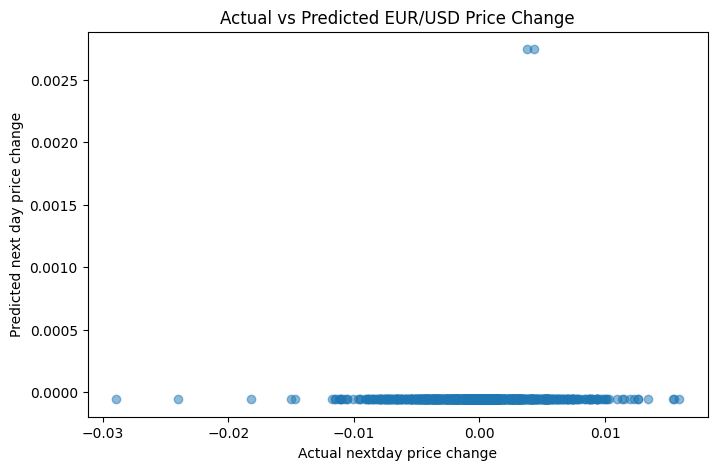

In [58]:
#now visualize the actual and prediction values
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.scatter(comparison["Actual"],comparison["Prediction"], alpha=0.5)
plt.xlabel("Actual nextday price change")
plt.ylabel("Predicted next day price change")
plt.title("Actual vs Predicted EUR/USD Price Change")
plt.show()

          






In [59]:
#Residual Analysis
comparison["Residual"] = (comparison["Actual"]-comparison["Prediction"])
comparison.head()

,Actual,Prediction,Residual
0,-0.00086,-0.000058,-0.000802
1,0.00626,-0.000058,0.006318
2,-0.00195,-0.000058,-0.001892
3,-0.00429,-0.000058,-0.004232
4,0.00263,-0.000058,0.002688


<span style = "font-size:60px; color:green;">**Residual Distribution**</span>

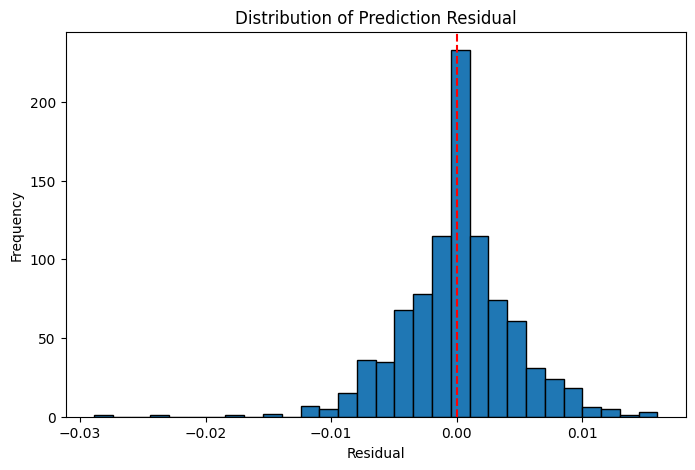

In [60]:
plt.figure(figsize=(8,5))
plt.hist(comparison["Residual"],bins=30,edgecolor="black")
plt.axvline(0,color="red", linestyle="--")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residual")
plt.show()



### **Model Evaluation Findings**

- The Decision Tree using `B_volatility` only (`max_depth=3`) had the lowest validation MAE among the models compared.
- On the 935 test observations, the model achieved an MAE of 0.00318030. The zero-change baseline achieved 0.00318183, a difference of about 0.048% in the model's favour.
- The model predicted approximately −0.000058 for 933 of the 935 test observations. Residuals were concentrated near zero, with some larger errors on both sides.

**Conclusion:** The model performed almost the same as the zero-change baseline on this test period. The small reduction in MAE provides little evidence of meaningful forecasting improvement.

